# Proyecto Final - Análisis de E-commerce Brasileño (Olist)

## Autor
María Alejandra Muñoz

## Objetivo

Analizar el comportamiento de las ventas del comercio electrónico brasileño utilizando Python, Power BI y GitHub para identificar patrones de compra, estados de pedidos y métodos de pago.

## Pregunta de negocio

¿Cómo evolucionan las ventas del comercio electrónico y cuáles son los factores más relevantes relacionados con la gestión de pedidos y los métodos de pago?

## Dataset

Brazilian E-Commerce Public Dataset by Olist.

Fuente:
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Carga de datos

Se cargaron los archivos principales del dataset:

- Clientes
- Pedidos
- Productos
- Pagos
- Detalle de pedidos

In [2]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")

In [3]:
print("Clientes:", customers.shape)
print("Pedidos:", orders.shape)
print("Items:", items.shape)
print("Pagos:", payments.shape)
print("Productos:", products.shape)

Clientes: (99441, 5)
Pedidos: (99441, 8)
Items: (112650, 7)
Pagos: (103886, 5)
Productos: (32951, 9)


In [4]:
print("Clientes:", customers.shape)
print("Pedidos:", orders.shape)
print("Items:", items.shape)
print("Pagos:", payments.shape)
print("Productos:", products.shape)

Clientes: (99441, 5)
Pedidos: (99441, 8)
Items: (112650, 7)
Pagos: (103886, 5)
Productos: (32951, 9)


In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [7]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [8]:
orders.shape

(99441, 8)

In [9]:
orders.isnull().sum()


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [10]:
orders.describe(include="all")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [11]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [12]:
estado_es = {
    "delivered": "Entregado",
    "shipped": "Enviado",
    "canceled": "Cancelado",
    "unavailable": "No disponible",
    "invoiced": "Facturado",
    "processing": "En proceso",
    "created": "Creado",
    "approved": "Aprobado"
}

orders["estado_pedido"] = orders["order_status"].map(estado_es)

orders["estado_pedido"].value_counts()

estado_pedido
Entregado        96478
Enviado           1107
Cancelado          625
No disponible      609
Facturado          314
En proceso         301
Creado               5
Aprobado             2
Name: count, dtype: int64

In [13]:
estado_es = {
    "delivered": "Entregado",
    "shipped": "Enviado",
    "canceled": "Cancelado",
    "unavailable": "No disponible",
    "invoiced": "Facturado",
    "processing": "En proceso",
    "created": "Creado",
    "approved": "Aprobado"
}

orders["estado_pedido"] = orders["order_status"].map(estado_es)

In [14]:
print(orders.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'estado_pedido']


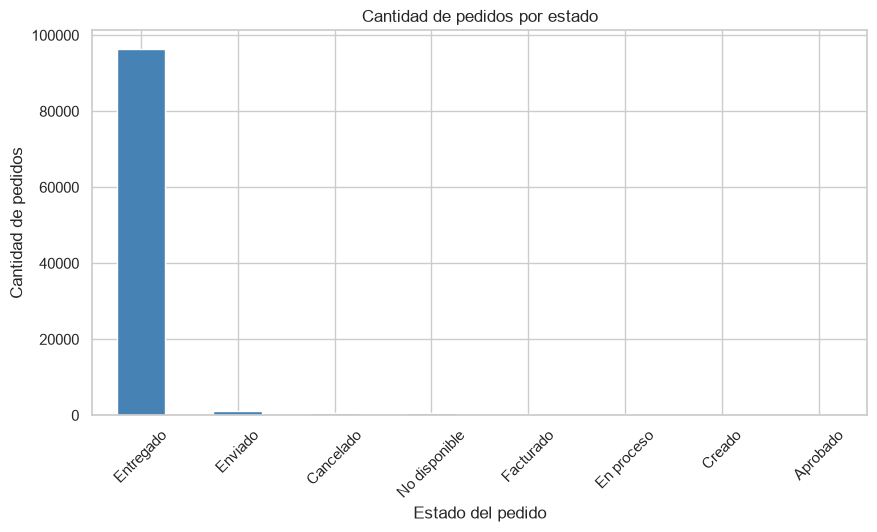

In [15]:
plt.figure(figsize=(10,5))

orders["estado_pedido"].value_counts().plot(
    kind="bar",
    color="steelblue"
)

plt.title("Cantidad de pedidos por estado")
plt.xlabel("Estado del pedido")
plt.ylabel("Cantidad de pedidos")

plt.xticks(rotation=45)

plt.show()

# Gráfico 1 - Estado de los pedidos

## Interpretación

La mayoría de los pedidos fueron entregados correctamente, alcanzando 96.478 registros.

Los pedidos cancelados, no disponibles y en proceso representan una proporción reducida respecto al total.

Esto sugiere un alto nivel de cumplimiento logístico por parte de la plataforma.

In [16]:
estado_resumen = (
    orders["estado_pedido"]
    .value_counts()
    .reset_index()
)

estado_resumen.columns = [
    "Estado del pedido",
    "Cantidad"
]

estado_resumen


,Estado del pedido,Cantidad
0,Entregado,96478
1,Enviado,1107
2,Cancelado,625
3,No disponible,609
4,Facturado,314
5,En proceso,301
6,Creado,5
7,Aprobado,2


### Interpretación

La mayoría de los pedidos fueron entregados correctamente, alcanzando 96.478 registros. Los estados "Enviado", "Cancelado" y "No disponible" representan una proporción muy pequeña respecto al total. Esto sugiere un alto nivel de cumplimiento en el proceso de entrega de pedidos.

In [17]:
estado_pct = (
    orders["estado_pedido"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

estado_pct

estado_pedido
Entregado        97.02
Enviado           1.11
Cancelado         0.63
No disponible     0.61
Facturado         0.32
En proceso        0.30
Creado            0.01
Aprobado          0.00
Name: proportion, dtype: float64

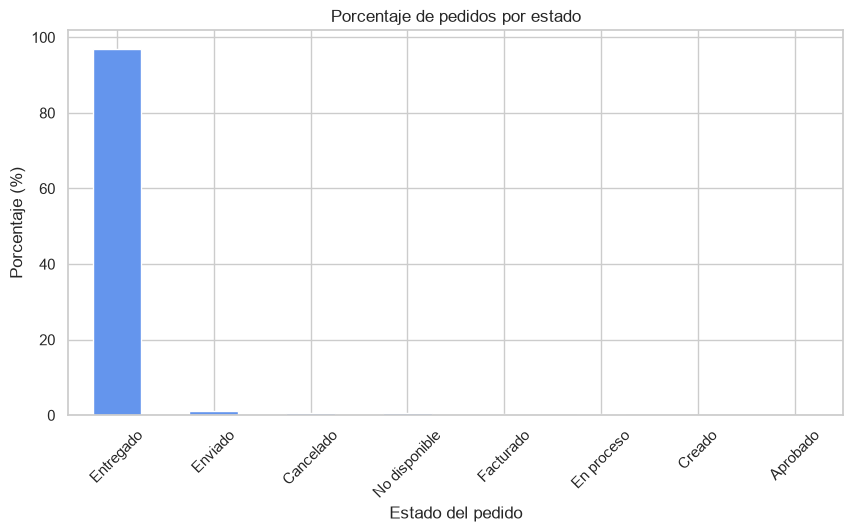

In [18]:
plt.figure(figsize=(10,5))

estado_pct.plot(
    kind="bar",
    color="cornflowerblue"
)

plt.title("Porcentaje de pedidos por estado")
plt.xlabel("Estado del pedido")
plt.ylabel("Porcentaje (%)")

plt.xticks(rotation=45)

plt.show()

In [19]:
payments["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [20]:
pagos_es = {
    "credit_card": "Tarjeta de crédito",
    "boleto": "Boleto bancario",
    "voucher": "Vale",
    "debit_card": "Tarjeta de débito",
    "not_defined": "No definido"
}

payments["tipo_pago"] = payments["payment_type"].map(pagos_es)

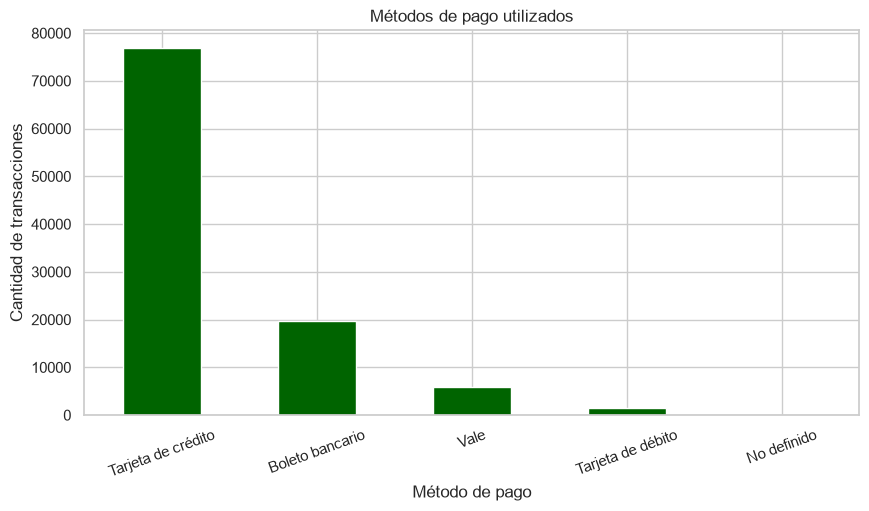

In [21]:
plt.figure(figsize=(10,5))

payments["tipo_pago"].value_counts().plot(
    kind="bar",
    color="darkgreen"
)

plt.title("Métodos de pago utilizados")
plt.xlabel("Método de pago")
plt.ylabel("Cantidad de transacciones")

plt.xticks(rotation=20)

plt.show()

### Interpretación

La tarjeta de crédito es el método de pago predominante, con 76.795 transacciones registradas. En segundo lugar se encuentra el boleto bancario con 19.784 transacciones. Los vales y las tarjetas de débito presentan una participación considerablemente menor, mientras que los registros sin método de pago definido son prácticamente inexistentes.

In [22]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

orders["año"] = orders["order_purchase_timestamp"].dt.year

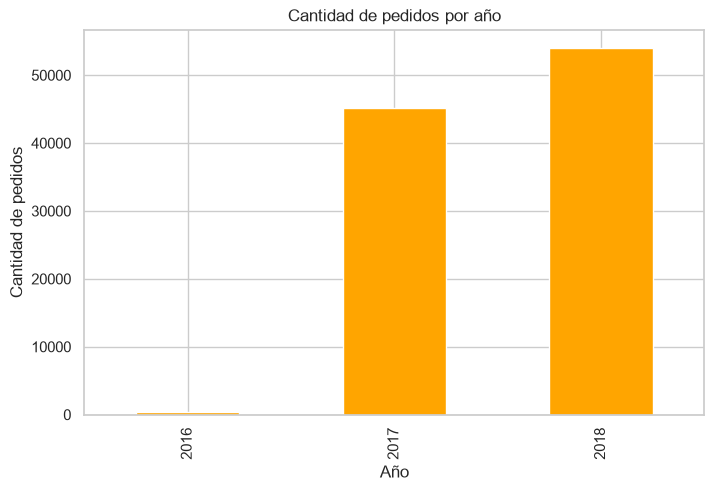

In [23]:
plt.figure(figsize=(8,5))

orders["año"].value_counts().sort_index().plot(
    kind="bar",
    color="orange"
)

plt.title("Cantidad de pedidos por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de pedidos")

plt.show()

In [24]:
pagos_es = {
    "credit_card": "Tarjeta de crédito",
    "boleto": "Boleto bancario",
    "voucher": "Vale",
    "debit_card": "Tarjeta de débito",
    "not_defined": "No definido"
}

payments["tipo_pago"] = payments["payment_type"].map(pagos_es)

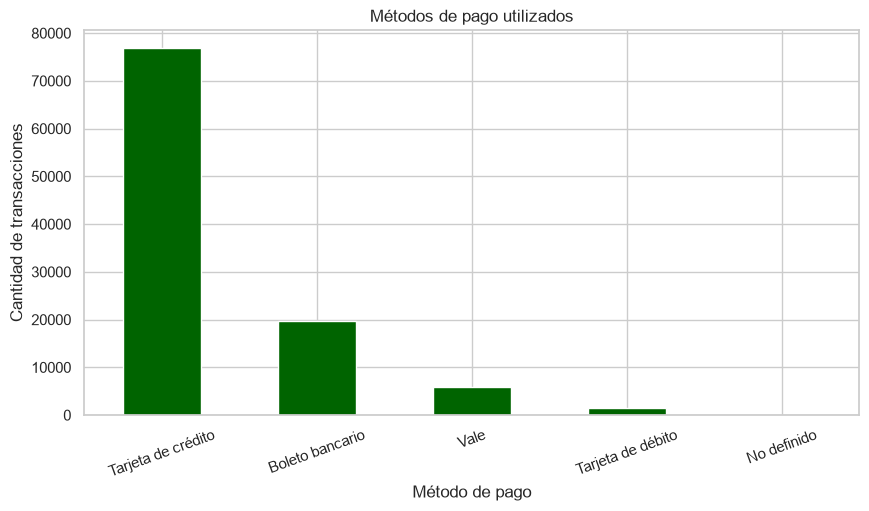

In [25]:
plt.figure(figsize=(10,5))

payments["tipo_pago"].value_counts().plot(
    kind="bar",
    color="darkgreen"
)

plt.title("Métodos de pago utilizados")
plt.xlabel("Método de pago")
plt.ylabel("Cantidad de transacciones")

plt.xticks(rotation=20)

plt.show()

# Gráfico 2 - Métodos de pago

## Interpretación

La tarjeta de crédito es el método de pago más utilizado, con 76.795 transacciones registradas.

El boleto bancario ocupa el segundo lugar con 19.784 transacciones.

Las opciones de vale y tarjeta de débito presentan una participación considerablemente menor, mientras que los registros sin método de pago definido son prácticamente inexistentes.

Estos resultados muestran una clara preferencia de los clientes por los medios de pago electrónicos, especialmente las tarjetas de crédito.

Conclusiones
Resumen del análisis

Se analizó el conjunto de datos Brazilian E-Commerce Public Dataset by Olist con el objetivo de comprender el comportamiento de las ventas, los estados de los pedidos y los métodos de pago utilizados por los clientes.

Durante la fase de exploración se realizó una auditoría de los datos, verificando tipos de datos, valores nulos y distribución de las variables principales.

Principales hallazgos
Estado de los pedidos

La mayoría de los pedidos fueron entregados correctamente, alcanzando 96.478 registros sobre un total de 99.441 pedidos.

Los pedidos cancelados, no disponibles o en proceso representan una proporción reducida, lo que evidencia una alta tasa de cumplimiento en la gestión logística.

Métodos de pago

La tarjeta de crédito se posiciona como el método de pago más utilizado por los clientes, seguida del boleto bancario.

Los pagos mediante vale y tarjeta de débito presentan una participación menor dentro del volumen total de transacciones.

Conclusiones generales

Los resultados permiten identificar un ecosistema de comercio electrónico con una elevada tasa de entrega exitosa y una clara preferencia por los pagos electrónicos.

La predominancia de las tarjetas de crédito sugiere una fuerte adopción de medios digitales de pago por parte de los consumidores.

Asimismo, el reducido porcentaje de pedidos cancelados indica que los procesos de compra y distribución muestran un nivel adecuado de eficiencia operativa.Próximos pasos

Como trabajo futuro, se recomienda profundizar el análisis incorporando:

Evolución temporal de las ventas.
Análisis por categoría de producto.
Análisis geográfico por estado o ciudad.
Construcción de un dashboard interactivo en Power BI.


In [26]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

In [27]:
orders["año"] = orders["order_purchase_timestamp"].dt.year
orders["mes"] = orders["order_purchase_timestamp"].dt.month

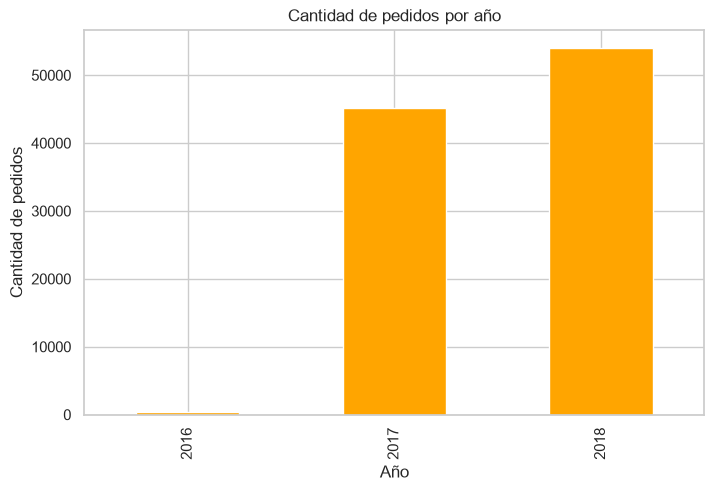

In [28]:
pedidos_por_año = (
    orders["año"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8,5))

pedidos_por_año.plot(
    kind="bar",
    color="orange"
)

plt.title("Cantidad de pedidos por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de pedidos")

plt.show()

# Gráfico 3 - Evolución temporal de los pedidos

## Interpretación

Este gráfico permite observar la evolución de la cantidad de pedidos a lo largo del tiempo.

El comportamiento de los pedidos muestra la dinámica del comercio electrónico durante los años analizados y permite identificar períodos de crecimiento o disminución en la actividad comercial.

Esta información resulta útil para comprender tendencias de consumo y apoyar la toma de decisiones estratégicas.

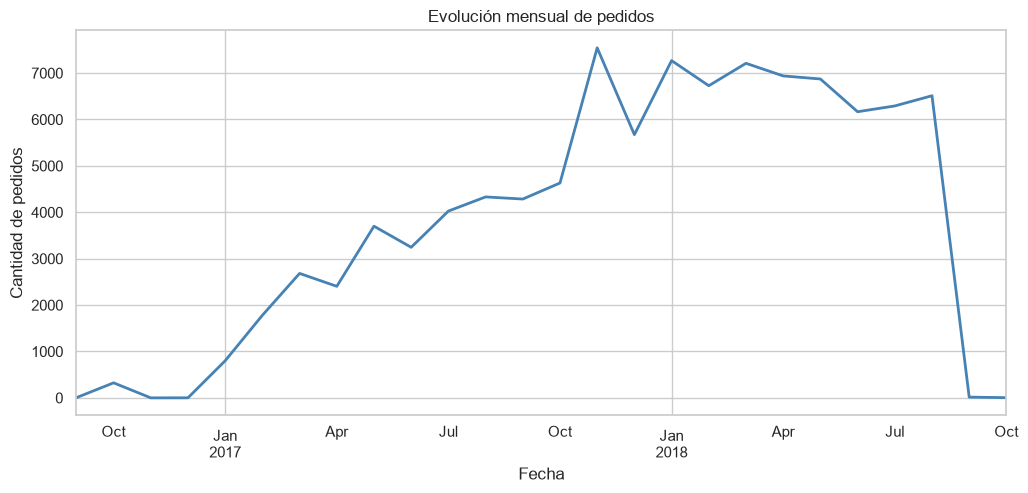

In [30]:
pedidos_mes = (
    orders
    .set_index("order_purchase_timestamp")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12,5))

pedidos_mes.plot(
    color="steelblue",
    linewidth=2
)

plt.title("Evolución mensual de pedidos")
plt.xlabel("Fecha")
plt.ylabel("Cantidad de pedidos")

plt.show()

# Gráfico 3 - Evolución mensual de pedidos

## Interpretación

La evolución temporal permite observar cambios en la cantidad de pedidos a lo largo del tiempo.

Este análisis ayuda a identificar tendencias de crecimiento, períodos de mayor actividad comercial y posibles comportamientos estacionales en el comercio electrónico.

La información obtenida resulta útil para la planificación de estrategias comerciales y la gestión de la demanda.

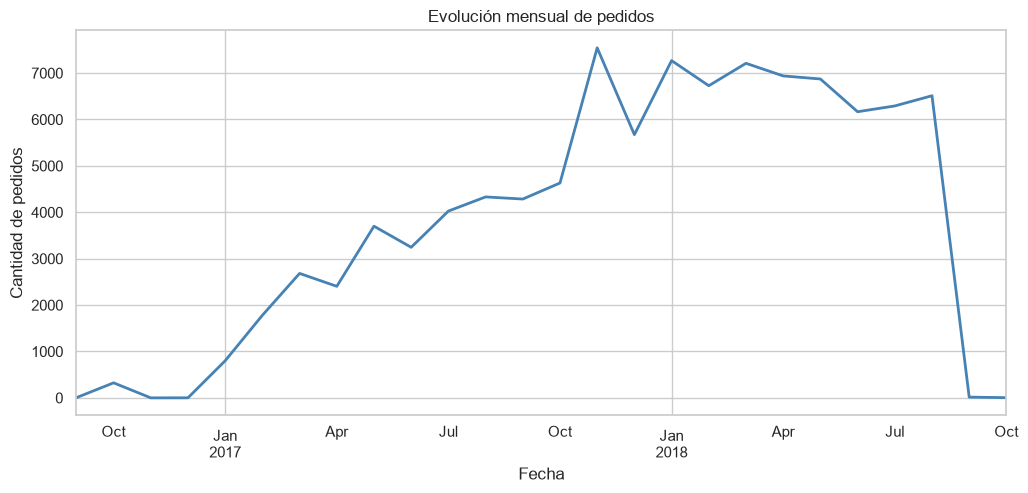

In [31]:
pedidos_mes = (
    orders
    .set_index("order_purchase_timestamp")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12,5))

pedidos_mes.plot(
    color="steelblue",
    linewidth=2
)

plt.title("Evolución mensual de pedidos")
plt.xlabel("Fecha")
plt.ylabel("Cantidad de pedidos")

plt.show()

# Gráfico 4 - Evolución mensual de pedidos

## Interpretación

La evolución mensual permite observar el comportamiento de la demanda a lo largo del tiempo.

Este análisis facilita la identificación de tendencias, períodos de crecimiento y posibles patrones estacionales en el comercio electrónico.

La información obtenida puede utilizarse para planificar estrategias comerciales y optimizar la gestión operativa.


# Proyecto Final - Análisis de E-commerce Brasileño (Olist)

## Autor
María Alejandra Muñoz

## Objetivo

Analizar el comportamiento de las ventas del comercio electrónico brasileño utilizando Python, Power BI y GitHub.

## Pregunta de negocio

¿Cómo evolucionan las ventas del comercio electrónico y cuáles son los factores más relevantes relacionados con los pedidos y los métodos de pago?

## Dataset

Brazilian E-Commerce Public Dataset by Olist.

# Conclusiones

## Hallazgos principales

- El 97% de los pedidos fueron entregados correctamente.
- La tarjeta de crédito es el método de pago predominante.
- Los pedidos cancelados representan una proporción reducida del total.
- La evolución temporal permite identificar variaciones en la actividad comercial a lo largo del tiempo.

## Conclusión general

El análisis muestra un ecosistema de comercio electrónico consolidado, con altos niveles de cumplimiento en las entregas y una fuerte preferencia por los medios de pago digitales.

La información obtenida permite comprender mejor el comportamiento de los clientes y constituye una base sólida para la construcción de dashboards y análisis de negocio más avanzados.

# Proyecto Final - Análisis de E-commerce Brasileño (Olist)

**Autor:** María Alejandra Muñoz

## Objetivo

Analizar el comportamiento de las ventas del comercio electrónico brasileño utilizando Python, Power BI y GitHub para identificar patrones de compra, métodos de pago predominantes y categorías de productos relevantes.

## Pregunta de negocio

¿Cómo evolucionan las ventas del comercio electrónico y cuáles son los factores más relevantes asociados a los pedidos y métodos de pago?

## Dataset

Brazilian E-Commerce Public Dataset by Olist.

Fuente:
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

## Herramientas utilizadas

- Python
- Pandas
- Matplotlib
- Seaborn
- Power BI
- GitHub

## Metodología

1. Carga y limpieza de datos.
2. Auditoría de calidad.
3. Exploración de datos.
4. Creación de visualizaciones.
5. Construcción de dashboard en Power BI.
6. Publicación en GitHub.

## Principales hallazgos

- La mayoría de los pedidos fueron entregados correctamente.
- La tarjeta de crédito representa el principal método de pago.
- Existen categorías de productos con una participación significativamente mayor.
- El ticket promedio supera los 15 mil.

## Estructura del repositorio

- data/
- notebooks/
- dashboard/
- images/

## Recursos

Dataset:
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce